# 4. Retention, Churn, and Funnel Analysis
Measure monthly cohorts, inactivity-based churn, and conversion drop-off for growth planning.

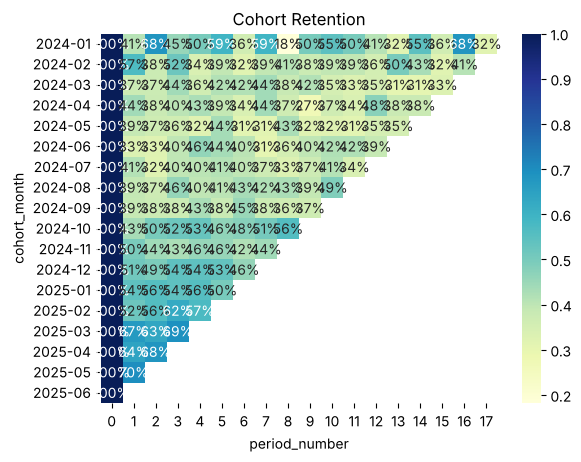

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
cohort = pd.read_csv(ROOT / 'data' / 'processed' / 'cohort_retention.csv')
matrix = cohort.pivot(index='cohort_month', columns='period_number', values='retention_rate')
sns.heatmap(matrix, annot=True, fmt='.0%', cmap='YlGnBu'); plt.title('Cohort Retention'); plt.show()

In [2]:
customers = pd.read_csv(ROOT / 'data' / 'processed' / 'customers_summary.csv')
churn = customers.groupby(['segment','customer_acquisition_channel']).is_churned.mean().unstack()
display(churn.style.format('{:.1%}'))
funnel = pd.read_csv(ROOT / 'data' / 'processed' / 'funnel_clean.csv')
funnel[['website_sessions','product_views','add_to_cart','checkout_started','purchases']].sum()

customer_acquisition_channel,Affiliate,Direct,Email,Organic Search,Paid Search,Social
segment,,,,,,
At Risk,33.3%,39.6%,24.6%,32.9%,29.9%,31.7%
Champions,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Lost Customers,48.4%,40.9%,41.0%,40.4%,46.0%,42.5%
Loyal Customers,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
New Customers,66.7%,50.0%,55.6%,71.4%,33.3%,28.6%
Potential Loyalists,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


website_sessions    336031
product_views       234888
add_to_cart          51052
checkout_started     32041
purchases            22272
dtype: int64